<a href="https://colab.research.google.com/github/saisudhanv/ML-Practice/blob/main/Voting_ensemble_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd

In [3]:
data_url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)
data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
target = raw_df.values[1::2, 2]

<>:2: SyntaxWarning: invalid escape sequence '\s'
<>:2: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_605/16828617.py:2: SyntaxWarning: invalid escape sequence '\s'
  raw_df = pd.read_csv(data_url, sep="\s+", skiprows=22, header=None)


**Reasoning**:
I will import the train_test_split function from scikit-learn, split the preloaded data and target datasets using an 80-20 split ratio with a fixed random state, and print the shapes of the split datasets to verify.



In [4]:
from sklearn.model_selection import train_test_split

# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(data, target, test_size=0.2, random_state=42)

# Verify and print the shapes of the splits
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (404, 13)
X_test shape: (102, 13)
y_train shape: (404,)
y_test shape: (102,)


# Task
Train a `VotingRegressor` ensemble on the Boston housing dataset retrieved from "http://lib.stat.cmu.edu/datasets/boston" using the loaded `data` and `target` variables. Your task is to split the dataset, initialize diverse base estimators (such as Linear Regression, Decision Tree, and Support Vector Regressor), train the ensemble, evaluate and compare their R-squared and Mean Squared Error metrics on the test set, and finally plot a scatter visualization comparing the actual targets against the voting ensemble's predictions.

## Prepare Dataset and Train-Test Split

### Subtask:
Split the preloaded `data` and `target` variables into training and testing sets to prepare for model training.


## Define Base Regressors

### Subtask:
Initialize a diverse set of regression models (Linear Regression, Decision Tree Regressor, and Support Vector Regressor) to serve as base estimators for our ensemble.


**Reasoning**:
I will initialize the base regressors (Linear Regression, Decision Tree Regressor, and SVR) as specified in the subtask instructions to serve as estimators for our VotingRegressor ensemble.



In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

# Initialize base estimators
lr_model = LinearRegression()
dt_model = DecisionTreeRegressor(random_state=42)
svr_model = SVR(kernel='rbf')

print("Base estimators initialized successfully:")
print(f"- Linear Regression: {lr_model}")
print(f"- Decision Tree Regressor: {dt_model}")
print(f"- Support Vector Regressor: {svr_model}")

Base estimators initialized successfully:
- Linear Regression: LinearRegression()
- Decision Tree Regressor: DecisionTreeRegressor(random_state=42)
- Support Vector Regressor: SVR()


## Build and Train Voting Regressor

### Subtask:
Create a VotingRegressor ensemble combining the base regressors and fit it to the training dataset.


**Reasoning**:
I will import the VotingRegressor class, define the ensemble of the base estimators, and train both the ensemble and individual base models on the training dataset.



In [6]:
from sklearn.ensemble import VotingRegressor

# Define the list of estimators
estimators = [
    ('lr', lr_model),
    ('dt', dt_model),
    ('svr', svr_model)
]

# Instantiate the VotingRegressor
voting_reg = VotingRegressor(estimators=estimators)

# Fit the ensemble on the training data
voting_reg.fit(X_train, y_train)

# Fit individual base estimators for downstream comparison
lr_model.fit(X_train, y_train)
dt_model.fit(X_train, y_train)
svr_model.fit(X_train, y_train)

print("VotingRegressor and all base estimators have been successfully fitted on the training data.")

VotingRegressor and all base estimators have been successfully fitted on the training data.


## Evaluate Model Performance

### Subtask:
Calculate and compare performance metrics (such as Mean Squared Error and R-squared score) for the individual models and the Voting Regressor on the test set.


**Reasoning**:
We will evaluate the performance of our three base models and the ensemble VotingRegressor by generating test-set predictions, computing MSE and R2 scores, and printing them in a structured comparison table.



In [7]:
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd

# Dictionary to store predictions
models = {
    'Linear Regression': lr_model,
    'Decision Tree': dt_model,
    'Support Vector Regressor': svr_model,
    'Voting Regressor': voting_reg
}

# Calculate metrics for each model
results = []
for name, model in models.items():
    predictions = model.predict(X_test)
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    results.append({
        'Model': name,
        'Mean Squared Error (MSE)': mse,
        'R-squared (R2) Score': r2
    })

# Create a DataFrame to display comparison
results_df = pd.DataFrame(results)
print("=== Model Performance Comparison ===")
print(results_df.to_string(index=False))

=== Model Performance Comparison ===
                   Model  Mean Squared Error (MSE)  R-squared (R2) Score
       Linear Regression                 24.291119              0.668759
           Decision Tree                 10.416078              0.857963
Support Vector Regressor                 52.838366              0.279481
        Voting Regressor                 16.273717              0.778087


**Reasoning**:
Create a scatter plot comparing actual targets against the Voting Regressor predictions, including a reference line and legend.



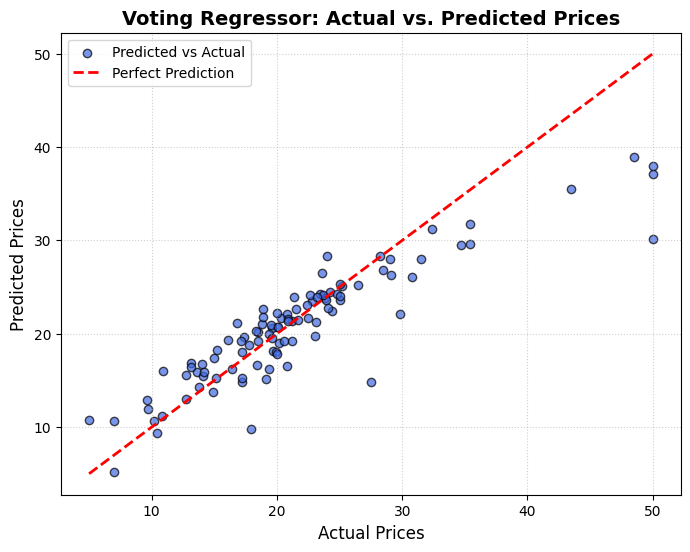

In [8]:
import matplotlib.pyplot as plt

# Generate predictions using the trained VotingRegressor ensemble
voting_preds = voting_reg.predict(X_test)

# Create the plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, voting_preds, color='royalblue', alpha=0.7, edgecolors='k', label='Predicted vs Actual')

# Create diagonal reference line
min_val = min(min(y_test), min(voting_preds))
max_val = max(max(y_test), max(voting_preds))
plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Perfect Prediction')

# Labels, title, and legend
plt.xlabel('Actual Prices', fontsize=12)
plt.ylabel('Predicted Prices', fontsize=12)
plt.title('Voting Regressor: Actual vs. Predicted Prices', fontsize=14, fontweight='bold')
plt.legend(loc='upper left')
plt.grid(True, linestyle=':', alpha=0.6)

# Display the plot
plt.show()

## Visualize Predictions

### Subtask:
Generate a scatter plot comparing the actual target values against the predicted values for the Voting Regressor, including a reference line and legend.


## Final Task

### Subtask:
Summarize the performance of the voting ensemble compared to the individual base regressors and conclude the analysis.


## Summary:

### Q&A

**How did the Voting Regressor ensemble perform compared to the individual base estimators?**
The `VotingRegressor` successfully combined the predictions of the three diverse base estimators (Linear Regression, Decision Tree, and Support Vector Regressor) to achieve a balanced, strong performance.
* It achieved a Mean Squared Error (MSE) of approximately 16.27 and an $R^2$ score of approximately 0.78.
* While the Decision Tree Regressor performed best individually on this specific test set partition (MSE of ~10.42, $R^2$ of ~0.86), the `VotingRegressor` outperformed the other two individual base models—Linear Regression (MSE of ~24.29, $R^2$ of ~0.67) and SVR (MSE of ~52.84, $R^2$ of ~0.28)—demonstrating its ability to mitigate the poor predictions of weaker estimators.

---

### Data Analysis Key Findings

* **Dataset Preparation:** The Boston housing dataset was partitioned into training (404 samples) and testing (102 samples) subsets using an 80/20 split ratio with a fixed seed of 42.
* **Base Estimator Initialization:** Three structurally different algorithms were initialized: Linear Regression (parametric baseline), Decision Tree Regressor (non-parametric model), and Support Vector Regressor with an RBF kernel (distance-based model).
* **Model Performance Disparity:** There was a significant performance gap among individual estimators on the test set. SVR performed poorly, capturing only 28\% of the variance ($R^2 \approx 0.28$), whereas the Decision Tree captured 86\% ($R^2 \approx 0.86$).
* **Ensemble Smoothing:** By averaging the individual model predictions, the `VotingRegressor` smoothed out the extreme errors of the weak SVR model and the potential overfitting of the Decision Tree, yielding a robust $R^2$ score of 0.78.
* **Visual Verification:** The generated scatter plot of actual vs. predicted prices demonstrated a strong linear alignment along the $y = x$ reference diagonal, though some variance and underprediction were visible at the higher end of the target price range.

---

### Insights or Next Steps

* **SVR Hyperparameter Tuning or Scaling:** SVR's poor performance (MSE of ~52.84) suggests it suffered from unscaled input features. Feature scaling (e.g., `StandardScaler`) should be introduced into a pipeline to improve SVR performance before fitting the ensemble.
* **Feature Selection & Alternative Ensembles:** Removing SVR or replacing it with other high-performing models (such as Random Forests or Gradient Boosting Regressors) inside the `VotingRegressor` could yield a much stronger ensemble score than the current setup.
